# Aula 8: Modelos de Linguagem de Grande Escala (LLMs)

Este notebook acompanha os slides da **Aula 8**. Na Aula 7 (RAG), o LLM recebia evidências do acervo; aqui abrimos a "caixa" e vemos **o que o LLM calcula**: a probabilidade do próximo token.

Todos os experimentos usam o `llama3.2` (3B) rodando localmente no **Ollama**, com `temperature = 0` e `seed = 42` sempre que o resultado precisa ser reprodutível. Usamos `num_gpu = 0` (CPU) para reproduzir os números dos slides: na GPU, as contas em ponto flutuante seguem outra ordem e as probabilidades mudam um pouco (por exemplo, 0,775 em vez de 0,752). O cache de *prompt* do Ollama também pode deslocar a terceira casa decimal entre execuções.

**Roteiro:** próximo token → tokens (BPE passo a passo) → arquitetura → embeddings e vizinhos → janela de contexto → atenção (à mão) → temperatura e *top-p* → amostragem → completar × conversar → *prompting* (few-shot, cadeia de raciocínio, JSON).

### **Passo 1: Preparação**
Instale o [Ollama](https://ollama.com), baixe o modelo com `ollama pull llama3.2` e instale as bibliotecas Python abaixo. O Ollama precisa estar rodando (`ollama serve`).

In [ ]:
# !pip install requests numpy matplotlib gguf regex

In [1]:
import requests, math, json
import numpy as np
import matplotlib.pyplot as plt

URL = "http://localhost:11434/api/"
MODELO = "llama3.2:latest"

def gerar(prompt, n=1, top=10, **opcoes):
    """Completa o texto cru (sem formato de conversa) e devolve as probabilidades de cada token gerado."""
    o = {"temperature": 0, "seed": 42, "num_predict": n, "num_gpu": 0}; o.update(opcoes)
    return requests.post(URL + "generate", json={"model": MODELO, "prompt": prompt, "raw": True, "stream": False,
                         "logprobs": True, "top_logprobs": top, "options": o}).json()

def conversar(mensagens, formato=None, **opcoes):
    """Usa o formato de conversa (modelo instruído)."""
    o = {"temperature": 0, "seed": 42, "num_gpu": 0}; o.update(opcoes)
    corpo = {"model": MODELO, "messages": mensagens, "stream": False, "options": o}
    if formato: corpo["format"] = formato
    return requests.post(URL + "chat", json=corpo).json()["message"]["content"]

print(requests.get(URL + "version").json())

{'version': '0.34.0'}


### **Passo 2: O próximo token**
Um LLM calcula $P(w_t \mid w_1,\dots,w_{t-1})$: a probabilidade de cada token do vocabulário vir em seguida. O Ollama devolve essas probabilidades em `logprobs` (logaritmo natural da probabilidade).

' Bel'       0.740
' a'         0.226
' o'         0.011
' Mac'       0.003
' Be'        0.002
' uma'       0.001
' Sant'      0.001
' mac'       0.001
' Br'        0.001
'Bel'        0.000


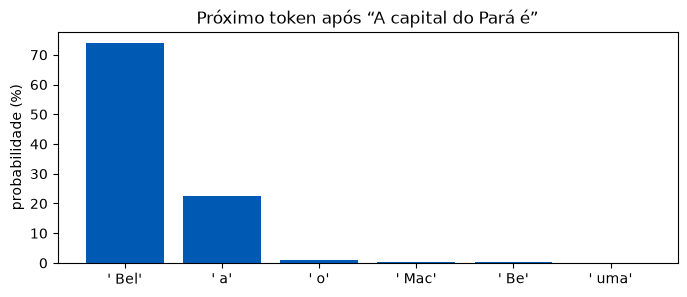

In [2]:
P1 = "A capital do Pará é"
r = gerar(P1, n=1, top=10)
cand = [(c["token"], math.exp(c["logprob"])) for c in r["logprobs"][0]["top_logprobs"]]
for t, p in cand:
    print(f"{t!r:12} {p:.3f}")

plt.figure(figsize=(8, 3))
plt.bar([repr(t) for t, _ in cand[:6]], [100 * p for _, p in cand[:6]], color="#005AB4")
plt.ylabel("probabilidade (%)"); plt.title(f"Próximo token após “{P1}”"); plt.show()

#### **Interpretação:**
- O token `' Bel'` (início de "Belém") recebe cerca de **75%** da probabilidade; `' a'` fica com cerca de 21%.
- O modelo **não consulta um banco de fatos**: ele escolhe tokens prováveis. Aqui o provável coincide com o verdadeiro porque o fato aparece muito nos dados de treino.

In [ ]:
r = gerar(P1, n=8, top=3)
print("Continuação gulosa:", repr(r["response"]))
for s in r["logprobs"]:
    print(f'{s["token"]!r:12} p = {math.exp(s["logprob"]):.3f}')

### **Passo 3: Tokenização exata do `llama3.2`**
O modelo não lê palavras: lê **tokens** (subpalavras, BPE). Vamos ler o vocabulário diretamente do arquivo do modelo baixado pelo Ollama (formato GGUF) e reproduzir o tokenizador.

In [4]:
import re, os, gguf, regex, functools
# caminho do arquivo do modelo, informado pelo próprio Ollama
mf = requests.post(URL + "show", json={"model": MODELO}).json()["modelfile"]
BLOB = re.search(r"^FROM (\S+)", mf, re.M).group(1)
if not os.access(BLOB, os.R_OK):   # o servidor pode guardar os modelos em outra pasta; procuramos o mesmo arquivo
    nome = os.path.basename(BLOB)
    BLOB = next(p for p in [os.path.expanduser("~/.ollama/models/blobs/" + nome), "/var/snap/ollama/common/models/blobs/" + nome,
                            "/usr/share/ollama/.ollama/models/blobs/" + nome] if os.access(p, os.R_OK))
R = gguf.GGUFReader(BLOB)

def campo(nome):
    f = R.fields[nome]
    if len(f.data) == 1:
        v = f.parts[f.data[0]]
        return bytes(v).decode() if v.dtype.kind == "u" and v.dtype.itemsize == 1 else v.tolist()[0]
    return [bytes(f.parts[i]).decode("utf-8", errors="replace") for i in f.data]

TOK = campo("tokenizer.ggml.tokens"); MER = campo("tokenizer.ggml.merges")
RANK = {tuple(m.split(" ")): i for i, m in enumerate(MER)}
print("vocabulário:", len(TOK), "tokens |", len(MER), "regras de junção (merges)")

vocabulário: 128256 tokens | 280147 regras de junção (merges)


In [5]:
# BPE em nível de byte (mesmo esquema do GPT-2/Llama 3)
def _b2u():
    bs = list(range(ord("!"), ord("~")+1)) + list(range(ord("¡"), ord("¬")+1)) + list(range(ord("®"), ord("ÿ")+1)); cs = bs[:]; n = 0
    for b in range(256):
        if b not in bs: bs.append(b); cs.append(256 + n); n += 1
    return dict(zip(bs, map(chr, cs)))
B2U = _b2u(); U2B = {v: k for k, v in B2U.items()}
PAT = regex.compile(r"(?i:'s|'t|'re|'ve|'m|'ll|'d)|[^\r\n\p{L}\p{N}]?\p{L}+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]+[\r\n]*|\s*[\r\n]+|\s+(?!\S)|\s+")

@functools.lru_cache(None)
def bpe(peca):
    w = list(peca)
    while len(w) > 1:
        r, i = min((RANK.get((w[i], w[i+1]), 1e18), i) for i in range(len(w) - 1))
        if r == 1e18: break
        w = w[:i] + [w[i] + w[i+1]] + w[i+2:]
    return w

def tokenizar(texto):
    out = []
    for m in PAT.findall(texto):
        out += bpe("".join(B2U[b] for b in m.encode("utf-8")))
    return [bytes(U2B[c] for c in t).decode("utf-8", errors="replace") for t in out]

In [ ]:
frases = ["Inteligência Artificial", "heurística", "Cametá", "Sistemas de Informação",
          "A carga horária total do curso é de 3.332 horas.",
          "The total workload of the course is 3,332 hours."]
for f in frases:
    t = tokenizar(f)
    # conferência: o Ollama conta os tokens do prompt (+1 do token de início <|begin_of_text|>)
    n_ollama = requests.post(URL + "generate", json={"model": MODELO, "prompt": f, "raw": True, "stream": False,
                             "options": {"num_predict": 1, "num_gpu": 0}}).json()["prompt_eval_count"]
    print(f"{len(t):2d} tokens (Ollama: {n_ollama - 1}) | {f!r}\n    {t}")

#### **Interpretação:**
- Palavras comuns viram um token (`' Artificial'`); palavras raras são quebradas (`'he' 'ur' 'ística'`).
- A mesma frase gastou **15 tokens em português** e **13 em inglês**: custo e limite de contexto são medidos em tokens.
- Os números são cortados em grupos de até 3 dígitos: `'3' '.' '332'`.
- A contagem coincide com a do próprio Ollama, o que confirma que o tokenizador reproduzido está correto.

### **Passo 3b: O BPE passo a passo**
O tokenizador começa com os **bytes** do texto e junta, a cada passo, o par vizinho com a regra de junção mais antiga (menor número de ordem na lista `MER`, aprendida no treino). Vamos acompanhar as junções em *" Belém"*.

In [6]:
def tracar(texto):
    w = list("".join(B2U[b] for b in texto.encode("utf-8")))
    ver = lambda x: bytes(U2B[c] for c in x).decode("utf-8", errors="replace").replace(" ", "␣")
    print("bytes:", [ver(x) for x in w], f"({len(w)} bytes)")
    while len(w) > 1:
        r, i = min((RANK.get((w[i], w[i+1]), 1e18), i) for i in range(len(w) - 1))
        if r == 1e18: break
        par = (ver(w[i]), ver(w[i+1])); w = w[:i] + [w[i] + w[i+1]] + w[i+2:]
        print(f"regra {r:>6}: {par[0]} + {par[1]:6} -> {[ver(x) for x in w]}")
    ID = {t: i for i, t in enumerate(TOK)}
    print("ids:", [ID[x] for x in w])

tracar(" Belém")

bytes: ['␣', 'B', 'e', 'l', '�', '�', 'm'] (7 bytes)
regra     64: e + l      -> ['␣', 'B', 'el', '�', '�', 'm']
regra    279: ␣ + B      -> ['␣B', 'el', '�', '�', 'm']
regra   1476: � + �      -> ['␣B', 'el', 'é', 'm']
regra  20953: ␣B + el     -> ['␣Bel', 'é', 'm']
regra  45696: é + m      -> ['␣Bel', 'ém']
ids: [7984, 17060]


#### **Interpretação:**
- *" Belém"* começa como **7 bytes**: o "é" ocupa 2 bytes em UTF-8 (aparece como `�` `�` até ser juntado).
- Em **5 junções** (regras 64, 279, 1476, 20953 e 45696), sobram 2 tokens: `'␣Bel'` (id 7984) e `'ém'` (id 17060).
- As regras mais antigas (números menores) juntam pares muito frequentes, como `e`+`l`; as mais novas, pares raros. Teste `tracar(" heurística")`.

### **Passo 4: A arquitetura, lida do arquivo do modelo**

In [7]:
for k in ["general.name", "general.size_label", "llama.context_length", "llama.embedding_length", "llama.block_count",
          "llama.attention.head_count", "llama.attention.head_count_kv", "llama.feed_forward_length"]:
    print(f"{k:32} {campo(k)}")

general.name                     Llama 3.2 3B Instruct
general.size_label               3B
llama.context_length             131072
llama.embedding_length           3072
llama.block_count                28
llama.attention.head_count       24
llama.attention.head_count_kv    8
llama.feed_forward_length        8192


In [8]:
tpl = requests.post(URL + "show", json={"model": MODELO}).json()["template"]
print([linha for linha in tpl.splitlines() if "Knowledge" in linha])

['Cutting Knowledge Date: December 2023']


#### **Interpretação:**
- **28 camadas** Transformer. Cada token é um vetor de **3.072** dimensões.
- **24 cabeças** de atenção compartilham **8 grupos** de chave e valor (*grouped-query attention*).
- O modelo foi treinado para até **131.072 tokens** de contexto. O Ollama usa uma janela menor por padrão (opção `num_ctx`; veja o Passo 4c).
- O próprio *template* de conversa declara o **corte de conhecimento**: *Cutting Knowledge Date: December 2023*. O que aconteceu depois disso o modelo não viu no treino.

### **Passo 4b: A tabela de *embeddings* e os vizinhos**
Cada id de token indexa uma linha da tabela `token_embd.weight`: **128.256 linhas × 3.072 números**, aprendidas no treino. Vamos ler a tabela do arquivo do modelo e procurar os vizinhos mais próximos pelo **cosseno**.
> Atenção: a tabela ocupa cerca de 1,6 GB na memória (precisa de uns 4 GB de RAM livres).

In [10]:
ten = next(t for t in R.tensors if t.name == "token_embd.weight")
E = gguf.quants.dequantize(ten.data, ten.tensor_type).astype(np.float32)   # (128256, 3072)
print("tipo:", ten.tensor_type.name, "| forma:", E.shape)
E /= np.linalg.norm(E, axis=1, keepdims=True)                              # normaliza: cosseno = produto escalar
ID = {t: i for i, t in enumerate(TOK)}
ver = lambda t: bytes(U2B[c] for c in t).decode("utf-8", errors="replace")

def vizinhos(palavra, k=5):
    i = ID["".join(B2U[b] for b in palavra.encode("utf-8"))]
    s = E @ E[i]
    return [(ver(TOK[j]), round(float(s[j]), 3)) for j in np.argsort(-s)[1:k + 1]]

for p in [" cidade", " Brasil", " professor", " segunda"]:
    print(f"{p!r:14}", vizinhos(p))

tipo: Q6_K | forma: (128256, 3072)
' cidade'      [(' città', 0.684), (' ciudad', 0.644), ('cidade', 0.623), ('-city', 0.575), ('(city', 0.567)]
' Brasil'      [(' Brazil', 0.62), ('Brazil', 0.603), (' brasile', 0.555), (' brazil', 0.551), (' Brazilian', 0.517)]
' professor'   [(' Professor', 0.776), (' professors', 0.758), ('Professor', 0.729), ('prof', 0.522), ('教授', 0.517)]
' segunda'     [('second', 0.615), (' segundo', 0.596), ('(second', 0.583), (' ikinci', 0.575), (' SECOND', 0.561)]


#### **Interpretação:**
- O vizinho de `' cidade'` é `' città'` (italiano), depois `' ciudad'` (espanhol); o de `' Brasil'` é `' Brazil'`; entre os de `' professor'` está `'教授'` (professor, em chinês).
- Tokens com significado parecido ficam próximos, mesmo em línguas diferentes.
- Esta é a tabela de **entrada**: cada token tem sempre o mesmo vetor, **sem contexto**. Quem mistura o contexto são as camadas do Transformer (Passo 5).

### **Passo 4c: A janela de contexto do Ollama**
O modelo foi treinado para até 131.072 tokens, mas o Ollama reserva por padrão uma janela bem menor. Vamos enviar um texto de ~14 mil tokens e ver quantos ele **processa** (`prompt_eval_count`), com e sem a opção `num_ctx`.

In [11]:
import subprocess
try:   # se tiver o PPC (ppc.pdf) nesta pasta, usamos o mesmo trecho do vídeo
    texto = subprocess.run(["pdftotext", "-layout", "ppc.pdf", "-"], capture_output=True, text=True, check=True).stdout[:60000]
except Exception:
    texto = " ".join(f"Item {i}: o curso de Sistemas de Informação tem disciplinas de fundamentos, tecnologia e gestão." for i in range(560))   # ~14 mil tokens
n = len(tokenizar(texto)) + 1   # +1: token de início
for opc in [{}, {"num_ctx": 16384}]:
    r = gerar(texto, n=1, top=1, **opc)
    print(f"{str(opc):20} enviados: {n:6d} | processados: {r['prompt_eval_count']}")
print(requests.get(URL + "ps").json()["models"][0].get("context_length"), "= janela reservada agora")

{}                   enviados:  14001 | processados: 2050


KeyboardInterrupt: 

#### **Interpretação:**
- Com a configuração padrão (no nosso PC, janela de 4.096), o Ollama processou só **2.050** tokens (no vídeo, com o trecho do PPC: 2.050 de 14.174). Ele descartou o **começo** e manteve o fim; o modelo não viu o resto.
- Repare: quando o texto não cabe, o Ollama ficou com cerca de **metade da janela** (2.050 ≈ 4.096 ÷ 2). Num teste com 20 mil tokens e `num_ctx = 16384`, ele também processou cerca de metade: 8.194.
- Com `num_ctx = 16384` e um texto que cabe na janela, processou todos. Janelas maiores custam mais memória e tempo.
- O valor padrão muda com a versão do Ollama e a máquina; confira sempre o `prompt_eval_count`.
- É por isso que o RAG (Aula 7) envia só os trechos relevantes, e não o documento inteiro.

### **Passo 5: Autoatenção à mão (a Questão dos slides)**
$$\text{Atenção}(Q,K,V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$$
Conferimos com `numpy` o exercício resolvido nos slides: a consulta do token *Pará* contra as chaves de *capital*, *do* e *Pará*.

In [12]:
q = np.array([1, 0, 1, 0.])                                  # consulta de "Pará"
K = np.array([[1, 0, 1, 0], [0, 1, 0, 0], [1, 1, 0, 0.]])    # chaves: capital, do, Pará
V = np.array([[1, 0], [0, 1], [1, 1.]])                      # valores
s = K @ q / np.sqrt(4)                                       # Passo 1: escores
alfa = np.exp(s) / np.exp(s).sum()                           # Passo 2: softmax
o = alfa @ V                                                 # Passo 3: saída ponderada
print("escores:", s); print("pesos:", alfa.round(3)); print("saída:", o.round(3))

escores: [1.  0.  0.5]
pesos: [0.506 0.186 0.307]
saída: [0.814 0.494]


#### **Interpretação:**
- Pesos ≈ **(0,506; 0,186; 0,307)**: *capital* é o token que mais influencia a nova representação de *Pará*.
- Num modelo real, essa conta acontece em 24 cabeças por camada, em 28 camadas, com vetores muito maiores.

### **Passo 6: Temperatura**
$$p_i = \frac{e^{z_i/T}}{\sum_j e^{z_j/T}}$$
Os `logprobs` servem como escores $z_i$ (a softmax não muda se somarmos uma constante a todos). Recalculamos a distribuição entre os 20 tokens mais prováveis.

massa dos 20 mais prováveis: 0.984
T = 0.5: P(' Bel') = 0.928
T = 1.0: P(' Bel') = 0.764
T = 1.5: P(' Bel') = 0.612


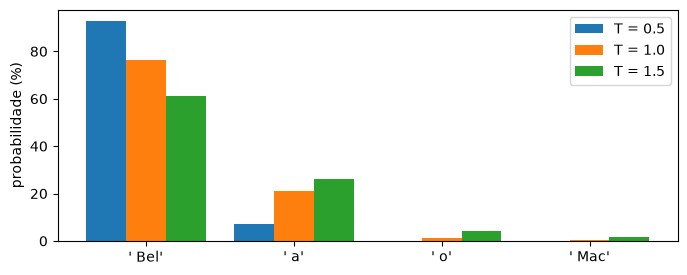

In [13]:
r = gerar(P1, n=1, top=20)
toks = [c["token"] for c in r["logprobs"][0]["top_logprobs"]]
z = np.array([c["logprob"] for c in r["logprobs"][0]["top_logprobs"]])
print(f"massa dos 20 mais prováveis: {np.exp(z).sum():.3f}")

def softmax_T(z, T):
    e = np.exp((z - z.max()) / T); return e / e.sum()

plt.figure(figsize=(8, 3)); x = np.arange(4); larg = 0.27
for i, T in enumerate([0.5, 1.0, 1.5]):
    p = softmax_T(z, T)
    print(f"T = {T}: P({toks[0]!r}) = {p[0]:.3f}")
    plt.bar(x + (i - 1) * larg, 100 * p[:4], larg, label=f"T = {T}")
plt.xticks(x, [repr(t) for t in toks[:4]]); plt.ylabel("probabilidade (%)"); plt.legend(); plt.show()

#### **Interpretação:**
- $T = 0{,}5$ concentra: `' Bel'` vai a ≈ 93%. $T = 1{,}5$ espalha: `' Bel'` cai para ≈ 61%.
- Com $T \to 0$, a escolha vira gulosa (sempre o favorito).

### **Passo 7: *Top-p* (amostragem por núcleo)**
Sorteia apenas no menor conjunto de tokens cuja probabilidade somada atinge $p$.

In [14]:
p = np.exp(z); acum = 0; nucleo = []
for t, pi in zip(toks, p):
    nucleo.append(t); acum += pi
    if acum >= 0.9: break
print("núcleo (p = 0,9):", nucleo, f"massa = {acum:.3f}")

núcleo (p = 0,9): [' Bel', ' a'] massa = 0.960


### **Passo 8: Amostragem real com 20 sementes**

In [15]:
P2 = "Um bom nome para um projeto de IA na UFPA Cametá é"
for T in [0.0, 0.7, 1.5]:
    respostas = [requests.post(URL + "generate", json={"model": MODELO, "prompt": P2, "raw": True, "stream": False,
                 "options": {"temperature": T, "seed": s, "num_predict": 10, "num_gpu": 0}}).json()["response"].strip() for s in range(1, 21)]
    print(f"T = {T}: {len(set(respostas))} respostas distintas em 20 | ex.: {respostas[:3]}")

T = 0.0: 1 respostas distintas em 20 | ex.: ['"CAMELIA" (Cametá', '"CAMELIA" (Cametá', '"CAMELIA" (Cametá']
T = 0.7: 19 respostas distintas em 20 | ex.: ['...?\nAtravés de uma pesquis', '"NEXUS-UFPA". Neste', '"Bem-Vindo ao Futuro" (']
T = 1.5: 20 respostas distintas em 20 | ex.: ['... como você não sabe?\n\n## Desenvolvimento', '"MindGeant" (A Mente É', '"Diversão e Científica",']


#### **Interpretação:**
- $T = 0$: as 20 sementes produzem **a mesma** resposta (decodificação determinística).
- $T = 0{,}7$: quase todas diferentes, ainda com sentido. $T = 1{,}5$: variedade máxima, com trechos sem sentido.
- Para tarefas factuais (extração, classificação), use temperatura baixa.

### **Passo 9: Completar texto × conversar (e a alucinação)**
O mesmo modelo, em dois formatos de entrada.

CONVERSA: Desculpe, mas não consegui encontrar informações atualizadas sobre a carga horária total do curso de Sistemas de Informação da UFPA Campus Cametá. A carga horária pode variar de ano para ano e pode ter sido alterada desde a última atualização das informações.

No entanto, posso sugerir algumas opçõe ...

COMPLETAR: ' 600 horas. A carga'
candidatos ao número: [('600', 0.078), ('240', 0.044), ('120', 0.044), ('300', 0.038), ('400', 0.035), ('960', 0.027), ('480', 0.024), ('100', 0.024), ('160', 0.023), ('180', 0.023)]


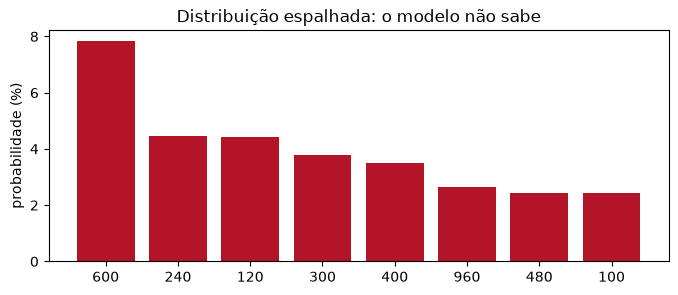

In [16]:
Q = "Qual a carga horária total do curso de Sistemas de Informação da UFPA Campus Cametá?"
print("CONVERSA:", conversar([{"role": "user", "content": Q}])[:300], "...\n")
r = gerar("A carga horária total do curso de Sistemas de Informação da UFPA Campus Cametá é de", n=6, top=10)
print("COMPLETAR:", repr(r["response"]))
passo = r["logprobs"][1]   # o token do número
cand = [(c["token"], math.exp(c["logprob"])) for c in passo["top_logprobs"]]
print("candidatos ao número:", [(t, round(p, 3)) for t, p in cand])
plt.figure(figsize=(8, 3)); plt.bar([t for t, _ in cand[:8]], [100 * p for _, p in cand[:8]], color="#B41428")
plt.ylabel("probabilidade (%)"); plt.title("Distribuição espalhada: o modelo não sabe"); plt.show()

#### **Interpretação:**
- Como completador de texto, o modelo escreve **"600 horas"**, mas o favorito tem só cerca de **8%** de probabilidade: a distribuição espalhada indica incerteza.
- No formato de conversa, o ajuste por instrução o leva a admitir que não encontrou a informação.
- O valor correto, no PPC, é **3.332 horas**: é exatamente o problema que o **RAG (Aula 7)** resolve, colocando o trecho certo no contexto.

### **Passo 10: *Zero-shot* × *few-shot***

In [17]:
COM = ["A professora explica muito bem, mas as provas são longas demais.",
       "Adorei o laboratório de IA!",
       "O ar-condicionado da sala nunca funciona."]
FS = ("Classifique o comentário como positivo, negativo ou misto. Responda só com a classe, em minúsculas.\n"
      "Comentário: As aulas práticas são excelentes.\nClasse: positivo\n"
      "Comentário: O laboratório vive sem internet.\nClasse: negativo\n"
      "Comentário: O professor é ótimo, mas a sala é apertada.\nClasse: misto\n"
      "Comentário: A cantina está sempre fechada.\nClasse: negativo\n")
for c in COM:
    zs = conversar([{"role": "user", "content": f"Classifique o comentário como positivo, negativo ou misto: {c}"}])
    fs = conversar([{"role": "user", "content": FS + f"Comentário: {c}\nClasse:"}]).strip()
    print(f"{c}\n   zero-shot: {zs[:90]!r}\n   few-shot : {fs!r}")

A professora explica muito bem, mas as provas são longas demais.
   zero-shot: 'Eu classificaria esse comentário como "misto".\n\nPor um lado, o comentário começa afirmando'
   few-shot : 'misto'
Adorei o laboratório de IA!
   zero-shot: 'O comentário é positivo.'
   few-shot : 'positivo'
O ar-condicionado da sala nunca funciona.
   zero-shot: 'Eu classificaria esse comentário como negativo. A afirmação "o ar-condicionado da sala nun'
   few-shot : 'negativo'


#### **Interpretação:**
- As duas versões acertam as classes, mas o *zero-shot* responde com frases longas e formatos variados.
- Com quatro exemplos no *prompt*, o *few-shot* devolve **uma palavra**, pronta para ser lida por código: os exemplos ensinam o formato e o rótulo esperado, sem treinar o modelo de novo.
- Mesmo assim, avalie com um conjunto de casos de resposta conhecida antes de confiar no classificador.

### **Passo 11: Cadeia de raciocínio (*chain-of-thought*)**

In [18]:
PB = ("Uma disciplina tem 68 horas-aula. Cada aula dura 2 horas-aula e acontece 2 vezes por semana. "
      "Quantas semanas dura a disciplina?")
print("DIRETO:", conversar([{"role": "user", "content": PB + " Responda apenas com o número."}]))
print("\nPASSO A PASSO:\n" + conversar([{"role": "user", "content": PB + " Pense passo a passo e, na última linha, escreva a resposta no formato 'Resposta: <número>'."}]))

DIRETO: 24

PASSO A PASSO:
Vamos resolver isso passo a passo:

1. Cada aula dura 2 horas-aula.
2. A disciplina tem 68 horas-aula.
3. Para saber quantas aulas são necessárias para a disciplina, dividimos o total de horas-aula pelo tempo de cada aula: 68 horas-aula / 2 horas-aula = 34 aulas.
4. A aula acontece 2 vezes por semana.
5. Para saber quantas semanas dura a disciplina, dividimos o número de aulas pelo número de aulas por semana: 34 aulas / 2 aulas/semana = 17 semanas.

Resposta: 17


#### **Interpretação:**
- Respondendo direto, o modelo erra (**24**). Escrevendo os passos ($68 \div 2 = 34$ aulas; $34 \div 2 = 17$ semanas), chega a **17**, o valor correto.
- Cada token gerado vira contexto para o próximo: os passos intermediários dão "espaço" para o cálculo.
- Repetimos 3 problemas 6 vezes cada: o passo a passo acertou em todas as execuções; a resposta direta errou sempre em 2 deles e oscilou no terceiro (veja o Desafio 5).

### **Passo 12: Papéis e saída estruturada (JSON)**

In [19]:
msgs = [{"role": "system", "content": "Você extrai dados e responde apenas em JSON."},
        {"role": "user", "content": 'Extraia {"disciplina", "carga_horaria", "semestre"} de: '
                                    '"INTELIGÊNCIA ARTIFICIAL (68 horas-aula), ofertada no 7º semestre."'}]
saida = conversar(msgs, formato="json")
dados = json.loads(saida)
print(dados)
assert set(dados) == {"disciplina", "carga_horaria", "semestre"}, "valide os campos!"

{'disciplina': 'INTELIGÊNCIA ARTIFICIAL', 'carga_horaria': '68 horas-aula', 'semestre': '7º'}


---
### **Desafio**
1. Repita o Passo 2 com *"A capital do Amapá é"*. A distribuição fica mais concentrada ou mais espalhada? Por quê?
2. No Passo 6, encontre a menor temperatura em que `' Bel'` passa de 99%.
3. No Passo 10, classifique também *"A biblioteca fecha cedo demais."*, *"O curso é ótimo, mas falta transporte à noite."* e *"Os monitores ajudam muito nas listas."*. O *few-shot* acerta todos? Monte um pequeno conjunto com gabarito e calcule a acurácia.
4. Use o pipeline do `RAG.ipynb` (Aula 7) para responder à pergunta do Passo 9 e compare com a resposta sem contexto.
5. No Passo 11, teste: *\"O curso tem 3.332 horas. Um estudante já cumpriu 2.380 horas e cursa, por semestre, 476 horas. Quantos semestres faltam para concluir?\"* (resposta: 2). Rode a resposta direta várias vezes: no nosso teste, ela oscilou entre 1 e 2. Por que a temperatura 0 não basta para garantir sempre a mesma resposta?

### ✅ Conclusão
Um LLM é um modelo de linguagem: a cada passo, ele calcula a probabilidade de cada token do vocabulário e escolhe um. Tokenização, atenção, temperatura e *prompts* são formas de entender e controlar esse cálculo. Quando o fato não está bem representado nos dados de treino, o provável pode ser falso; por isso o RAG coloca evidências no contexto.